___
<a href='https://honglab.ai'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 인컨텍스트 러닝

**해당 강의:** 파트3 챕터6 「인컨텍스트 러닝」

작은 트랜스포머로 강의의 실험 세 가지를 직접 돌립니다.

1. **그로킹** — 훈련 데이터를 다 외운 뒤 한참 지나서야 규칙을 깨칩니다.
2. **인덕션 헤드** — 앞에서 같은 단어를 찾아 그다음 단어를 베껴 옵니다. 1층과 2층 트랜스포머를 비교하고, 어텐션을 재서 이 일을 맡은 헤드를 찾습니다.
3. **상전이** — 이 능력이 훈련 도중 어느 순간 갑자기 생기는 것을 봅니다.

- 실행 시간: 3분 안팎 (CPU)
- 설치할 것: torch, matplotlib
- 데이터 파일은 필요 없습니다. 문제를 코드가 그 자리에서 만듭니다.
- CPU에서 몇 분 안에 끝나도록 강의 실험보다 모델과 문제를 줄였습니다. 그래서 수치가 강의와 조금 다릅니다.

In [1]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 그래프에 한글이 보이도록 설치된 한글 폰트를 찾아 씁니다 (윈도우·맥·리눅스 순)
installed = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in installed:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False

## 작은 트랜스포머

앞 노트북에서 만든 GPT와 같은 구조(RMSNorm, RoPE, 어텐션, SwiGLU)를 짧게 다시 적었습니다.
층마다 마지막으로 계산한 어텐션 가중치를 저장해 두어, 뒤에서 어디를 보는지 잴 수 있게 했습니다.

In [2]:
import math
import random
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)


class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def rope_tables(head_dim, max_len, theta=10000.0):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    emb = torch.outer(torch.arange(max_len).float(), inv_freq).repeat(1, 2)
    return emb.cos(), emb.sin()


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


class Attention(nn.Module):
    def __init__(self, d, n_head):
        super().__init__()
        self.n_head, self.head_dim = n_head, d // n_head
        self.wqkv = nn.Linear(d, 3 * d, bias=False)
        self.wo = nn.Linear(d, d, bias=False)
        self.attn = None                                  # 마지막으로 계산한 어텐션 가중치

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.wqkv(x).split(C, dim=-1)
        q, k, v = (t.view(B, T, self.n_head, self.head_dim).transpose(1, 2) for t in (q, k, v))
        q = q * cos[:T] + rotate_half(q) * sin[:T]        # RoPE
        k = k * cos[:T] + rotate_half(k) * sin[:T]
        mask = torch.triu(torch.full((T, T), float("-inf")), diagonal=1)
        att = (q @ k.transpose(-2, -1) / math.sqrt(self.head_dim) + mask).softmax(-1)
        self.attn = att.detach()
        return self.wo((att @ v).transpose(1, 2).reshape(B, T, C))


class SwiGLU(nn.Module):
    def __init__(self, d, d_ff):
        super().__init__()
        self.w_gate = nn.Linear(d, d_ff, bias=False)
        self.w_up = nn.Linear(d, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))


class Block(nn.Module):
    def __init__(self, d, n_head, d_ff):
        super().__init__()
        self.attn_norm, self.attn = RMSNorm(d), Attention(d, n_head)
        self.ffn_norm, self.ffn = RMSNorm(d), SwiGLU(d, d_ff)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.attn_norm(x), cos, sin)
        return x + self.ffn(self.ffn_norm(x))


class SmallGPT(nn.Module):
    def __init__(self, vocab_size, d=128, n_layer=2, n_head=4, max_len=64):
        super().__init__()
        d_ff = (int(8 / 3 * d) + 63) // 64 * 64
        self.token_emb = nn.Embedding(vocab_size, d)
        self.blocks = nn.ModuleList([Block(d, n_head, d_ff) for _ in range(n_layer)])
        self.final_norm = RMSNorm(d)
        self.lm_head = nn.Linear(d, vocab_size, bias=False)
        self.lm_head.weight = self.token_emb.weight      # 가중치 공유
        cos, sin = rope_tables(d // n_head, max_len)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)
        for name, p in self.named_parameters():
            if name.endswith("wo.weight") or name.endswith("w_down.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * n_layer))

    def forward(self, idx):
        x = self.token_emb(idx)
        for blk in self.blocks:
            x = blk(x, self.cos, self.sin)
        return self.lm_head(self.final_norm(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())

## 실험 1. 그로킹

(a + b) mod 31을 가르칩니다. a와 b가 0부터 30까지라서 문제는 31 × 31 = 961가지입니다.
그중 40%(384개)만 훈련에 쓰고, 나머지 60%는 숨겨 두었다가 검증에 씁니다. 규칙을 깨쳤을 때만 숨긴 문제도 맞힐 수 있습니다.

입력은 토큰 세 개입니다. 숫자 두 개와 등호(`=`)입니다. 모델은 등호 자리에서 답을 냅니다.

In [3]:
P = 31
EQ = P                                             # 등호 토큰 번호 (숫자 0–30 다음)
X = torch.tensor([[a, b, EQ] for a in range(P) for b in range(P)])
Y = (X[:, 0] + X[:, 1]) % P

perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
n_train = int(0.4 * len(X))
train_idx, val_idx = perm[:n_train], perm[n_train:]
print(f"문제 {len(X)}개 → 훈련 {len(train_idx)}개 · 검증 {len(val_idx)}개")
print("훈련 문제 예:", [f"{a}+{b}={(a + b) % P}" for a, b, _ in X[train_idx[:5]].tolist()])

torch.manual_seed(0)
grok_model = SmallGPT(P + 1, d=128, n_layer=2, n_head=4, max_len=4)
print(f"파라미터 {n_params(grok_model):,}개")

문제 961개 → 훈련 384개 · 검증 577개
훈련 문제 예: ['1+18=19', '28+12=9', '17+7=24', '17+8=25', '10+10=20']
파라미터 430,720개


훈련 문제 384개를 한 번에 넣는 전체 배치로 훈련합니다. 가중치 감쇠(weight decay)를 1.0으로 세게 줍니다.
가중치 감쇠는 가중치가 커지지 않게 누르는 장치인데, 그로킹을 또렷하게 만드는 핵심 조건입니다.

In [4]:
opt = torch.optim.AdamW(grok_model.parameters(), lr=1e-3, betas=(0.9, 0.98), weight_decay=1.0)

@torch.no_grad()
def accuracy(model, idx):
    return (model(X[idx])[:, -1].argmax(-1) == Y[idx]).float().mean().item()

grok = {"step": [], "train": [], "val": []}
t0 = time.time()
for step in range(2501):
    loss = F.cross_entropy(grok_model(X[train_idx])[:, -1], Y[train_idx])   # 등호 자리의 예측만 채점
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    if step % 25 == 0:
        grok["step"].append(step)
        grok["train"].append(accuracy(grok_model, train_idx))
        grok["val"].append(accuracy(grok_model, val_idx))
    if step % 500 == 0:
        print(f"step {step:>4} | 훈련 정확도 {grok['train'][-1]:.0%} | 검증 정확도 {grok['val'][-1]:.0%} | {time.time() - t0:.0f}초")

step    0 | 훈련 정확도 6% | 검증 정확도 2% | 0초


step  500 | 훈련 정확도 100% | 검증 정확도 38% | 9초


step 1000 | 훈련 정확도 100% | 검증 정확도 48% | 17초


step 1500 | 훈련 정확도 100% | 검증 정확도 84% | 26초


step 2000 | 훈련 정확도 100% | 검증 정확도 100% | 34초


step 2500 | 훈련 정확도 100% | 검증 정확도 96% | 43초


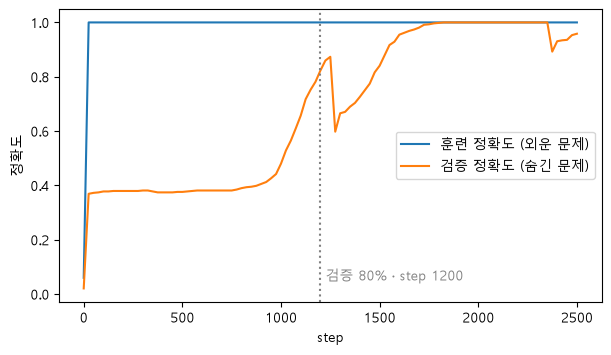

훈련 정확도 100%: step 25 · 검증 정확도 80%: step 1200 · 최종 검증 정확도 95.8%


In [5]:
memorized = next(s for s, a in zip(grok["step"], grok["train"]) if a == 1.0)
grokked = next((s for s, a in zip(grok["step"], grok["val"]) if a >= 0.8), None)

plt.figure(figsize=(7, 3.8))
plt.plot(grok["step"], grok["train"], label="훈련 정확도 (외운 문제)")
plt.plot(grok["step"], grok["val"], label="검증 정확도 (숨긴 문제)")
if grokked is not None:
    plt.axvline(grokked, color="gray", ls=":")
    plt.text(grokked, 0.05, f" 검증 80% · step {grokked}", color="gray")
plt.xlabel("step")
plt.ylabel("정확도")
plt.legend(loc="center right")
plt.show()
print(f"훈련 정확도 100%: step {memorized} · 검증 정확도 80%: step {grokked} · 최종 검증 정확도 {grok['val'][-1]:.1%}")

훈련 정확도는 금방 100%가 됩니다. 문제를 다 외운 것입니다. 하지만 숨긴 문제의 정확도는 한동안 낮게 머뭅니다.
훈련을 멈추지 않고 계속하면 어느 순간 검증 정확도가 가파르게 올라갑니다(올라가는 도중에 잠깐 출렁이기도 합니다). 다 외우고 한참 지나서야 규칙을 깨친 것입니다.

숨긴 문제 몇 개를 직접 물어봅니다.

In [6]:
with torch.no_grad():
    for a, b, _ in X[val_idx[:5]].tolist():
        pred = grok_model(torch.tensor([[a, b, EQ]]))[0, -1].argmax().item()
        print(f"{a:>2} + {b:>2} = ? (mod {P}) → 정답 {(a + b) % P:>2}, 모델 {pred:>2} {'✓' if pred == (a + b) % P else '✗'}")

 8 + 17 = ? (mod 31) → 정답 25, 모델 25 ✓
21 + 27 = ? (mod 31) → 정답 17, 모델 17 ✓
20 + 15 = ? (mod 31) → 정답  4, 모델  4 ✓
 0 + 26 = ? (mod 31) → 정답 26, 모델 26 ✓
14 + 13 = ? (mod 31) → 정답 27, 모델 27 ✓


## 실험 2. 인덕션 헤드 — 찾아서 베낀다

강의의 퀴즈 「자두 다음에 올 단어는?」을 떠올려 보세요. 앞에서 「자두 새벽」을 본 적이 있다면, 뜻을 몰라도 「새벽」이라고 답할 수 있습니다.
이번 문제가 그렇습니다. 무작위로 뽑은 단어 묶음이 같은 순서로 계속 반복됩니다. 묶음은 시퀀스마다 새로 뽑으므로 외울 수 없고, 둘째 바퀴부터는 앞을 찾아 베끼면 맞힙니다.
묶음의 길이(6–12단어)도 시퀀스마다 바꿉니다. 길이가 고정이면 「몇 칸 앞을 베껴라」 같은 지름길로 풀리기 때문입니다.

강의에서는 사전(단어 쌍)을 보여 주고 다시 묻는 문제를 썼습니다. 원리는 같지만 그 문제는 CPU로 몇 분 훈련해서는 성공할 때도 있고 아닐 때도 있어서, 여기서는 더 빨리 배우는 반복 문제를 씁니다.

In [7]:
WORDS = '''사자 코끼리 사과 망고 의자 지갑 자동차 피아노 호랑이 기린 바나나 키위 책상 안경 기차 기타
토끼 원숭이 포도 파인애플 침대 컵 비행기 바이올린 거북 판다 딸기 멜론 거울 접시 여객선 드럼
여우 표범 수박 체리 시계 숟가락 자전거 플루트 늑대 하마 참외 살구 우산 젓가락 버스 첼로
곰 코뿔소 복숭아 무화과 가방 베개 트럭 트럼펫 사슴 얼룩말 자두 석류 신발 이불 오토바이 하프'''.split()
V, T = len(WORDS), 32                              # 단어 64개(단어 하나 = 토큰 하나), 시퀀스 길이 32

def repeat_batch(B, rng):
    xs, ys = [], []
    for _ in range(B):
        p = rng.randint(6, 12)                     # 이번 시퀀스의 묶음 길이
        block = rng.sample(range(V), p)            # 서로 다른 단어 p개
        toks = [block[i % p] for i in range(T + 1)]
        xs.append(toks[:T])
        ys.append([toks[i + 1] if i + 1 >= p else -1 for i in range(T)])   # 첫 바퀴는 채점하지 않음(-1)
    return torch.tensor(xs), torch.tensor(ys)

def words_of(ids):
    return " ".join(WORDS[i] for i in ids)

x, y = repeat_batch(2, random.Random(5))
for row in x.tolist():
    print(words_of(row))

여우 첼로 비행기 복숭아 우산 베개 오토바이 하마 표범 코끼리 여우 첼로 비행기 복숭아 우산 베개 오토바이 하마 표범 코끼리 여우 첼로 비행기 복숭아 우산 베개 오토바이 하마 표범 코끼리 여우 첼로
석류 코뿔소 신발 기타 하마 망고 얼룩말 바나나 피아노 바이올린 여객선 이불 석류 코뿔소 신발 기타 하마 망고 얼룩말 바나나 피아노 바이올린 여객선 이불 석류 코뿔소 신발 기타 하마 망고 얼룩말 바나나


두 모델을 같은 데이터, 같은 목적(다음 단어 맞히기)으로 훈련합니다. 차이는 층 수뿐입니다.
평가는 처음 보는 시퀀스 512개의 둘째 바퀴 이후 자리에서 다음 단어를 맞힌 비율(적중률)로 잽니다. 무작위로 찍으면 1/64 ≈ 1.6%입니다.

In [8]:
eval_x, eval_y = repeat_batch(512, random.Random(999))

def train_repeat(n_layer, steps=2000):
    torch.manual_seed(0)
    rng = random.Random(0)
    model = SmallGPT(V, d=64, n_layer=n_layer, n_head=4, max_len=T)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.99), weight_decay=0.01)
    hist = {"step": [], "acc": []}
    t0 = time.time()
    for step in range(steps + 1):
        x, y = repeat_batch(128, rng)
        loss = F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1), ignore_index=-1)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if step % 50 == 0:
            with torch.no_grad():
                pred = model(eval_x).argmax(-1)
            mask = eval_y >= 0
            hist["step"].append(step)
            hist["acc"].append((pred[mask] == eval_y[mask]).float().mean().item())
    print(f"{n_layer}층: 파라미터 {n_params(model):,}개 | 최종 적중률 {hist['acc'][-1]:.1%} | {time.time() - t0:.0f}초")
    return model, hist

model2, hist2 = train_repeat(n_layer=2)
model1, hist1 = train_repeat(n_layer=1)

2층: 파라미터 110,912개 | 최종 적중률 99.6% | 45초


1층: 파라미터 57,536개 | 최종 적중률 43.6% | 30초


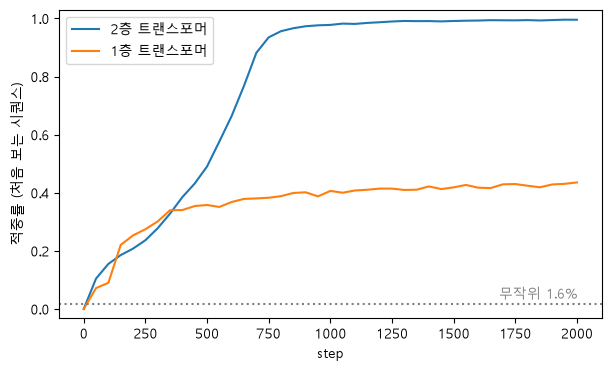

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(hist2["step"], hist2["acc"], label="2층 트랜스포머")
plt.plot(hist1["step"], hist1["acc"], label="1층 트랜스포머")
plt.axhline(1 / V, color="gray", ls=":")
plt.text(hist2["step"][-1], 1 / V + 0.02, "무작위 1.6%", color="gray", ha="right")
plt.xlabel("step")
plt.ylabel("적중률 (처음 보는 시퀀스)")
plt.ylim(-0.03, 1.03)
plt.legend()
plt.show()

2층은 거의 다 맞히고, 1층은 크게 못 미칩니다. 1층도 무작위보다는 높은데, 앞에 나온 단어들 가운데서 고르는 정도까지는 배웠기 때문으로 보입니다. 그중 어느 단어가 다음인지는 정확히 찾지 못합니다.

두 모델에게 같은 문제를 내 봅니다. 2층만 맞히는 자리를 하나 골라 보여 줍니다.

In [10]:
with torch.no_grad():
    p2, p1 = model2(eval_x).argmax(-1), model1(eval_x).argmax(-1)
def period_of(row):
    return row.index(row[0], 1)                    # 첫 단어가 다시 나오는 자리 = 묶음 길이

# 둘째 바퀴 이후(같은 단어가 앞에 나온 적 있는 자리)에서 2층만 맞힌 곳을 찾습니다
b, t = next((b, t) for b in range(len(eval_x)) for t in range(period_of(eval_x[b].tolist()), T)
            if p2[b, t] == eval_y[b, t] != p1[b, t])

row = eval_x[b].tolist()
period = period_of(row)
print("입력:", words_of(row[:t + 1]), "…")
print(f"({period}단어 묶음이 같은 순서로 반복)")
w = WORDS[row[t]]
print(f"질문: {row[:t + 1].count(row[t])}번째 「{w}」 다음은?  (앞에서 「{w}」 다음 단어: 「{WORDS[eval_y[b, t]]}」)")
print(f"  2층: 「{WORDS[p2[b, t]]}」 {'✓' if p2[b, t] == eval_y[b, t] else '✗'}")
print(f"  1층: 「{WORDS[p1[b, t]]}」 {'✓' if p1[b, t] == eval_y[b, t] else '✗'}")

입력:

 바나나 얼룩말 트럼펫 시계 신발 수박 드럼 여객선 호랑이 무화과 하마 침대 바나나 얼룩말 …
(12단어 묶음이 같은 순서로 반복)
질문: 2번째 「얼룩말」 다음은?  (앞에서 「얼룩말」 다음 단어: 「트럼펫」)
  2층: 「트럼펫」 ✓
  1층: 「수박」 ✗


### 어텐션을 재 본다

2층 트랜스포머는 이 문제를 두 단계로 풉니다.

1. **1층의 이전 토큰 헤드:** 각 단어가 바로 앞 단어를 보고 「내 앞에는 ○○」라는 꼬리표를 붙여 둡니다. 「새벽」에는 「앞에는 자두」가 붙습니다.
2. **2층의 인덕션 헤드:** 지금 자리의 「자두」가 「앞에는 자두」 꼬리표가 붙은 칸을 찾아가, 거기 있는 「새벽」을 베껴 옵니다.

정말 그렇게 하는지 처음 보는 시퀀스 512개에서 어텐션 가중치를 재 봅니다.

- 1층: 각 자리가 바로 앞 자리를 보는 비율
- 2층: 둘째 바퀴 이후의 자리가 「앞에서 같은 단어가 나온 자리의 바로 다음 칸」을 보는 비율

In [11]:
with torch.no_grad():
    model2(eval_x)
att1 = model2.blocks[0].attn.attn                 # (B, H, T, T) 1층
att2 = model2.blocks[1].attn.attn                 # 2층

pos = torch.arange(1, T)
prev = att1[:, :, pos, pos - 1].mean(dim=(0, 2))   # 바로 앞 자리를 보는 비율 (헤드별)
self_ = att1[:, :, pos, pos].mean(dim=(0, 2))      # 자기 자신을 보는 비율
uniform_prev = (1 / (pos + 1).float()).mean()      # 볼 수 있는 칸을 고르게 볼 때의 비율

ind, uniform_ind = [], []
for b, row in enumerate(eval_x.tolist()):
    p = period_of(row)                             # 묶음 길이
    ts = torch.arange(p, T)                        # 같은 단어가 앞에 나온 적 있는 자리들
    ind.append(att2[b, :, ts, ts - p + 1].mean(-1))   # 앞선 같은 단어의 다음 칸
    uniform_ind.append((1 / (ts + 1).float()).mean())
ind, uniform_ind = torch.stack(ind).mean(0), torch.stack(uniform_ind).mean()

print(f"(고르게 본다면: 바로 앞 단어 {uniform_prev:.0%}, 앞선 같은 단어의 다음 칸 {uniform_ind:.0%})")
for h in range(4):
    print(f"1층 헤드 {h}: 바로 앞 단어 {prev[h]:.0%} · 자기 자신 {self_[h]:.0%}")
print()
for h in range(4):
    print(f"2층 헤드 {h}: 앞선 같은 단어의 다음 칸 {ind[h]:.0%}")

(고르게 본다면: 바로 앞 단어 10%, 앞선 같은 단어의 다음 칸 5%)
1층 헤드 0: 바로 앞 단어 21% · 자기 자신 8%
1층 헤드 1: 바로 앞 단어 45% · 자기 자신 0%
1층 헤드 2: 바로 앞 단어 42% · 자기 자신 40%
1층 헤드 3: 바로 앞 단어 44% · 자기 자신 41%

2층 헤드 0: 앞선 같은 단어의 다음 칸 2%
2층 헤드 1: 앞선 같은 단어의 다음 칸 71%
2층 헤드 2: 앞선 같은 단어의 다음 칸 11%
2층 헤드 3: 앞선 같은 단어의 다음 칸 69%


2층에는 앞에서 같은 단어가 나온 자리의 다음 칸을, 고르게 볼 때보다 열 배 넘게 집중해서 보는 헤드가 있습니다. 이 헤드가 인덕션 헤드입니다.
1층에는 바로 앞 단어를 고르게 볼 때보다 몇 배 많이 보는 헤드들이 있습니다. 이전 토큰 헤드입니다.
다만 강의 실험(바로 앞 단어 98%)처럼 한 헤드에 몰려 있지는 않고, 40%대로 보는 헤드가 여럿입니다. 이 노트북의 작은 모델에서는 꼬리표 붙이는 일을 여러 헤드가 나눠 맡은 셈입니다.

한 시퀀스에서 두 헤드의 어텐션을 그려 봅니다. 왼쪽은 대각선 바로 아래 줄이, 오른쪽은 묶음 길이만큼 떨어진 사선이 밝게 나옵니다.

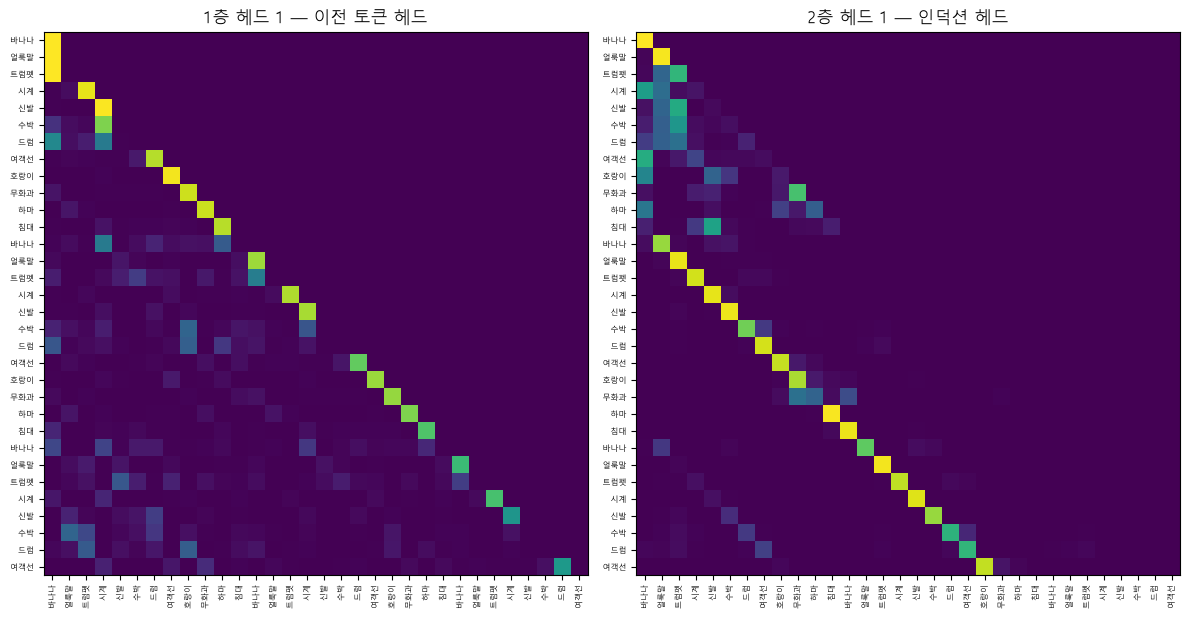

In [12]:
h1, h2 = prev.argmax().item(), ind.argmax().item()
row = eval_x[0].tolist()
labels = [WORDS[i] for i in row]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, att, title in [(axes[0], att1[0, h1], f"1층 헤드 {h1} — 이전 토큰 헤드"),
                       (axes[1], att2[0, h2], f"2층 헤드 {h2} — 인덕션 헤드")]:
    ax.imshow(att, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(T), labels, rotation=90, fontsize=6)
    ax.set_yticks(range(T), labels, fontsize=6)
    ax.set_title(title)
plt.tight_layout()
plt.show()

층이 하나뿐이면 꼬리표를 붙이는 단계와 꼬리표로 찾는 단계를 이어서 할 수 없습니다. 1층 모델이 풀지 못한 이유입니다.

## 실험 3. 상전이 — 능력은 갑자기 생긴다

이번에는 인덕션 헤드가 훈련 도중 「언제」 생기는지 봅니다. 무작위 단어 8–16개 묶음을 48단어가 될 때까지 반복해 주고, 모든 자리에서 다음 단어를 맞히게 합니다.
진짜 언어 모델을 훈련할 때처럼 「앞을 베껴라」는 지시는 어디에도 없습니다. 묶음 길이가 시퀀스마다 달라서 「몇 칸 앞을 베껴라」로는 풀 수 없고, 앞에서 같은 단어를 찾아야 합니다.
첫 바퀴는 무작위라 맞힐 수 없고, 둘째 바퀴부터는 앞을 베끼면 맞힙니다. 두 구간의 손실을 따로 재며 2층 모델을 훈련합니다.

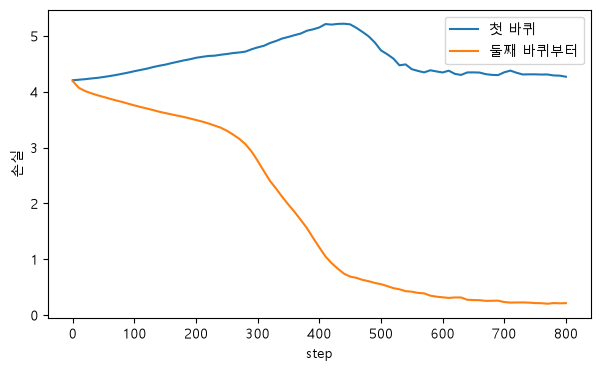

step   0 | 첫 바퀴 4.20 | 둘째 바퀴부터 4.19
step 200 | 첫 바퀴 4.61 | 둘째 바퀴부터 3.49
step 300 | 첫 바퀴 4.79 | 둘째 바퀴부터 2.76
step 400 | 첫 바퀴 5.15 | 둘째 바퀴부터 1.21
step 500 | 첫 바퀴 4.74 | 둘째 바퀴부터 0.55
step 800 | 첫 바퀴 4.27 | 둘째 바퀴부터 0.21
둘째 바퀴부터의 손실이 1 아래로 떨어진 때: step 420


In [13]:
L3 = 47                                            # 입력 길이 (48단어 중 마지막 단어는 정답으로만 씀)

def copy_batch(B, rng):
    xs, ys, ks = [], [], []
    for _ in range(B):
        k = rng.randint(8, 16)                     # 이번 시퀀스의 묶음 길이
        block = rng.sample(range(V), k)
        toks = [block[i % k] for i in range(L3 + 1)]
        xs.append(toks[:L3]); ys.append(toks[1:]); ks.append(k)
    return torch.tensor(xs), torch.tensor(ys), torch.tensor(ks)

torch.manual_seed(0)
rng = random.Random(0)
phase_model = SmallGPT(V, d=64, n_layer=2, n_head=4, max_len=L3)
opt = torch.optim.AdamW(phase_model.parameters(), lr=1e-3, betas=(0.9, 0.99), weight_decay=0.01)
ex, ey, ek = copy_batch(512, random.Random(999))
first_round = torch.arange(L3)[None, :] < (ek[:, None] - 1)   # 첫 바퀴 안의 다음 단어 (예측 불가)

phase = {"step": [], "첫 바퀴": [], "둘째 바퀴부터": []}
for step in range(801):
    x, y, _ = copy_batch(64, rng)
    loss = F.cross_entropy(phase_model(x).reshape(-1, V), y.reshape(-1))
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(phase_model.parameters(), 1.0)
    opt.step()
    if step % 10 == 0:
        with torch.no_grad():
            l = F.cross_entropy(phase_model(ex).reshape(-1, V), ey.reshape(-1), reduction="none").view(len(ex), L3)
        phase["step"].append(step)
        phase["첫 바퀴"].append(l[first_round].mean().item())
        phase["둘째 바퀴부터"].append(l[~first_round].mean().item())

plt.figure(figsize=(7, 4))
for name in ["첫 바퀴", "둘째 바퀴부터"]:
    plt.plot(phase["step"], phase[name], label=name)
plt.xlabel("step")
plt.ylabel("손실")
plt.legend()
plt.show()

for s in [0, 200, 300, 400, 500, 800]:
    i = phase["step"].index(s)
    print(f"step {s:>3} | 첫 바퀴 {phase['첫 바퀴'][i]:.2f} | 둘째 바퀴부터 {phase['둘째 바퀴부터'][i]:.2f}")
drop = next((s for s, l in zip(phase["step"], phase["둘째 바퀴부터"]) if l < 1.0), None)
print(f"둘째 바퀴부터의 손실이 1 아래로 떨어진 때: step {drop}")

둘째 바퀴부터의 손실은 한동안 천천히 내려가다가, 짧은 구간에서 절벽처럼 떨어집니다. 이때 앞에서 같은 단어를 찾아 베끼는 회로, 곧 인덕션 헤드가 만들어집니다.
첫 바퀴의 손실은 오르내리다가 처음과 비슷한 수준으로 돌아옵니다. 무작위로 뽑은 단어라 맞힐 방법이 없기 때문입니다.
전환 무렵 첫 바퀴의 손실이 잠깐 오르는 것은, 베끼기를 배우던 모델이 첫 바퀴에서도 앞에 나온 단어를 고르려다 틀리기 때문으로 보입니다. 첫 바퀴에서 다음 단어는 늘 처음 나오는 단어입니다.
능력이 서서히 차오르지 않고 어느 순간 갑자기 생기는 이런 변화를 상전이(phase change)라고 부릅니다.
떨어지는 시점은 컴퓨터나 파이토치 버전에 따라 조금 달라질 수 있습니다.

## 정리

- 그로킹: 훈련 데이터를 다 외운 뒤 한참 지나서야 처음 보는 문제까지 맞히게 됩니다.
- 인컨텍스트 러닝: 가중치를 바꾸지 않고 입력 안의 내용만 보고 답합니다. 2층 트랜스포머만 앞을 찾아 베끼는 문제를 풀었습니다.
- 인덕션 헤드: 1층의 이전 토큰 헤드가 꼬리표를 붙이고, 2층 헤드가 그 꼬리표로 찾아가 베껴 옵니다.
- 상전이: 이 회로는 훈련 도중 어느 순간 갑자기 만들어집니다.

강의 실험의 원래 크기 코드(사전 문제, NPLM 비교 포함)와 실행 결과는 실습 자료의 `exp04_icl_demos` 폴더에 있습니다.